# Modelling: abalone age prediction

We train a first set of models predicting the number of rings of an abalone (age = rings + 1.5) and track every
experiment with **MLflow**: parameters, cross-validation and test metrics, and the fitted model.

To browse and compare the experiments in the MLflow UI, run from the `notebooks` folder:

```bash
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5001
```

and open http://127.0.0.1:5001 (or run `make mlflow-ui` from the repository root).

# Imports

In [1]:
import logging
import pickle

import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from mlflow.models import infer_signature
from sklearn.base import RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Configuration

In [2]:
RANDOM_STATE = 42
TEST_SIZE = 0.2
# MLflow saves scikit-learn models with skops, which refuses to load tree structures unless they
# are explicitly trusted. We train these models ourselves, so we can trust them.
SKOPS_TRUSTED_TYPES = [
    "sklearn.tree._tree.Tree",
    "sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor",
]

# uv environments do not ship pip: hide MLflow's warning about its missing version
logging.getLogger("mlflow.utils.environment").setLevel(logging.ERROR)

mlflow.set_tracking_uri("sqlite:///mlflow.db")
experiment = mlflow.set_experiment("abalone-age-prediction")
print(f"MLflow experiment: {experiment.name} (id {experiment.experiment_id})")

2026/10/22 11:03:48 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/22 11:03:48 INFO mlflow.store.db.utils: Updating database tables


2026/10/22 11:03:49 INFO mlflow.tracking.fluent: Experiment with name 'abalone-age-prediction' does not exist. Creating a new experiment.


MLflow experiment: abalone-age-prediction (id 1)


# Data preparation

Same cleaning as the conclusions of the EDA: snake_case column names and removal of the 4 impossible heights.

In [3]:
COLUMNS_MAPPING = {
    "Sex": "sex",
    "Length": "length",
    "Diameter": "diameter",
    "Height": "height",
    "Whole weight": "whole_weight",
    "Shucked weight": "shucked_weight",
    "Viscera weight": "viscera_weight",
    "Shell weight": "shell_weight",
    "Rings": "rings",
}
CATEGORICAL_FEATURES = ["sex"]
NUMERICAL_FEATURES = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
]
TARGET = "rings"

df = pd.read_csv("../data/abalone.csv").rename(columns=COLUMNS_MAPPING)
df = df[(df["height"] > 0) & (df["height"] <= 0.4)].reset_index(drop=True)

X_train, X_test, y_train, y_test = train_test_split(
    df[CATEGORICAL_FEATURES + NUMERICAL_FEATURES],
    df[TARGET],
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)
print(f"Train set: {X_train.shape}, test set: {X_test.shape}")

Train set: (3338, 8), test set: (835, 8)


# Pipeline

Each model is a scikit-learn `Pipeline`: one-hot encoding of `sex` and scaling of the numerical features, followed
by the regressor. Saving the whole pipeline keeps the encoder and the model together, so the exact same
preprocessing is applied at training and at prediction time.

In [4]:
def build_pipeline(regressor: RegressorMixin) -> Pipeline:
    """Chain the preprocessing (one-hot encoding and scaling) with a regressor."""
    preprocessor = ColumnTransformer(
        transformers=[
            ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
            ("numerical", StandardScaler(), NUMERICAL_FEATURES),
        ]
    )
    return Pipeline(steps=[("preprocessor", preprocessor), ("regressor", regressor)])

# Experiments

Every candidate is evaluated with a 5-fold cross-validation on the train set (used to choose the model) and on the
held-out test set. Each candidate is one MLflow run.

In [5]:
candidates = {
    "mean_baseline": DummyRegressor(strategy="mean"),
    "linear_regression": LinearRegression(),
    "ridge": Ridge(alpha=1.0),
    "random_forest": RandomForestRegressor(
        n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE
    ),
    "gradient_boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE
    ),
    "hist_gradient_boosting": HistGradientBoostingRegressor(
        learning_rate=0.05, max_iter=300, min_samples_leaf=20, random_state=RANDOM_STATE
    ),
}

In [6]:
cross_validation = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
fitted_pipelines = {}

for model_name, regressor in candidates.items():
    pipeline = build_pipeline(regressor)
    with mlflow.start_run(run_name=model_name):
        cv_rmse = -cross_val_score(
            pipeline, X_train, y_train, cv=cross_validation, scoring="neg_root_mean_squared_error"
        )
        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        metrics = {
            "cv_rmse_mean": cv_rmse.mean(),
            "cv_rmse_std": cv_rmse.std(),
            "test_rmse": root_mean_squared_error(y_test, y_pred),
            "test_mae": mean_absolute_error(y_test, y_pred),
            "test_r2": r2_score(y_test, y_pred),
            "model_size_kb": len(pickle.dumps(pipeline)) / 1024,
        }
        mlflow.log_param("model", model_name)
        mlflow.log_params(regressor.get_params())
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(
            pipeline,
            name="model",
            signature=infer_signature(X_train, pipeline.predict(X_train)),
            input_example=X_train.head(3),
            skops_trusted_types=SKOPS_TRUSTED_TYPES,
        )
    results.append({"model": model_name, **metrics})
    fitted_pipelines[model_name] = pipeline

results_df = pd.DataFrame(results).set_index("model").sort_values("cv_rmse_mean")
results_df.round(3)

,cv_rmse_mean,cv_rmse_std,test_rmse,test_mae,test_r2,model_size_kb
model,,,,,,
random_forest,2.128,0.097,2.200,1.515,0.596,14335.974
gradient_boosting,2.166,0.098,2.190,1.521,0.600,396.584
ridge,2.177,0.106,2.229,1.584,0.586,2.369
linear_regression,2.177,0.105,2.229,1.584,0.585,2.425
hist_gradient_boosting,2.207,0.102,2.242,1.544,0.581,1057.009
mean_baseline,3.161,0.120,3.463,2.541,-0.001,2.186


# Model selection

The random forest has the lowest cross-validated RMSE, but its gap with gradient boosting (about 0.04 ring) is well
within the cross-validation noise (standard deviation of about 0.1), and gradient boosting is slightly better on
the test set. Gradient boosting is also about 35 times lighter (about 0.4 MB against 14 MB), which matters to
version the model, ship it in the Docker image of the API and load it quickly.

We therefore select the **gradient boosting** pipeline.

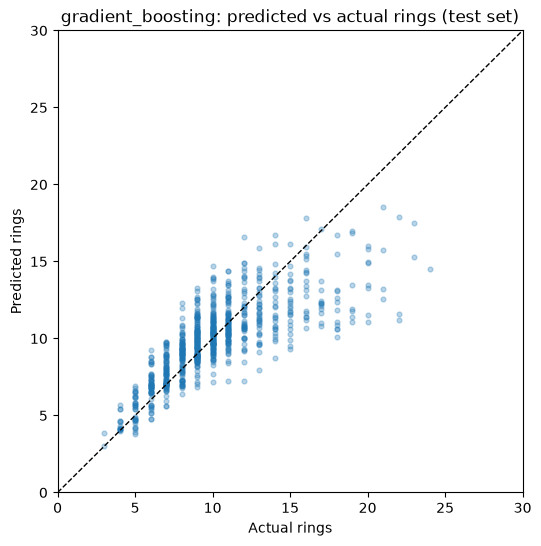

In [7]:
SELECTED_MODEL = "gradient_boosting"
y_pred = fitted_pipelines[SELECTED_MODEL].predict(X_test)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_pred, alpha=0.3, s=12)
ax.plot([0, 30], [0, 30], color="black", linestyle="--", linewidth=1)
ax.set(
    title=f"{SELECTED_MODEL}: predicted vs actual rings (test set)",
    xlabel="Actual rings",
    ylabel="Predicted rings",
    xlim=(0, 30),
    ylim=(0, 30),
)
plt.show()

# Conclusion

- Every model beats the mean baseline by far (cross-validated RMSE of 2.13 to 2.21 rings against 3.16).
- Selected model: **gradient boosting** (`n_estimators=300`, `learning_rate=0.05`, `max_depth=3`,
  `subsample=0.8`) after the preprocessing steps. On the test set: RMSE 2.19 rings, MAE 1.52 rings, R² 0.60.
- On average the predicted age is off by about 1.5 years. Old abalones (more than about 15 rings) are
  underestimated: once an abalone stops growing, its measurements barely change while its rings keep increasing.
- Next step: this pipeline is moved to the `src/modelling` modules, trained by a Prefect flow and served by the
  API.